In [1]:
print("CA1 - Retail Performance Analytics")
print("Python environment working!")

CA1 - Retail Performance Analytics
Python environment working!


In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load the retail dataset

retail = pd.read_csv("../data/retail/retail_outlets.csv")

# Display the first five rows
retail.head()

,StoreID,Region,StoreType,MarketingSpend,Footfall,OnlineTraffic,StaffHours,DiscountRate,CustomerSatisfaction,InventoryAvailability,CompetitorDistance,PreviousMonthSales,Season,SalesRevenue
0,1079,East,Town,5053.285500,945.839116,8264.861349,309.758037,26.886747,77.678159,97.759093,2.045180,48358.887458,Autumn,37269.08
1,1009,South,Town,5932.964720,1522.784544,10715.078680,500.225154,38.668926,67.495612,89.531440,4.137114,50390.304228,Spring,51422.51
2,1063,East,Mall,4835.839175,831.008509,5153.654601,350.276924,37.818931,72.180178,100.000000,6.237205,42753.480466,Summer,36453.33
3,1017,West,Mall,4363.678155,864.893490,11462.981788,361.549075,11.768159,75.852001,91.001755,7.365479,22733.450258,Winter,33589.20
4,1063,South,Retail Park,3979.351302,929.286725,13249.787137,415.528042,17.739506,66.982320,75.312714,8.164185,33612.871347,Spring,29145.07


In [3]:
# TASK 1: Data Preparation & Quality Assessment
# Requirement: Inspect dataset dimensions, column names and data types

print("Number of rows:", retail.shape[0])
print("Number of columns:", retail.shape[1])

print("\nColumn names:")
print(retail.columns.tolist())

print("\nDataset information:")
retail.info()

Number of rows: 5100
Number of columns: 14

Column names:
['StoreID', 'Region', 'StoreType', 'MarketingSpend', 'Footfall', 'OnlineTraffic', 'StaffHours', 'DiscountRate', 'CustomerSatisfaction', 'InventoryAvailability', 'CompetitorDistance', 'PreviousMonthSales', 'Season', 'SalesRevenue']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 5100 entries, 0 to 5099
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   StoreID                5100 non-null   int64  
 1   Region                 5100 non-null   str    
 2   StoreType              5100 non-null   str    
 3   MarketingSpend         4741 non-null   float64
 4   Footfall               5100 non-null   float64
 5   OnlineTraffic          4746 non-null   float64
 6   StaffHours             5100 non-null   float64
 7   DiscountRate           5100 non-null   float64
 8   CustomerSatisfaction   4741 non-null   float64
 9   InventoryAvailab

In [4]:
# TASK 1: Data Preparation & Quality Assessment
# Requirement: Produce summary statistics

retail.describe(include="all")

,StoreID,Region,StoreType,MarketingSpend,Footfall,OnlineTraffic,StaffHours,DiscountRate,CustomerSatisfaction,InventoryAvailability,CompetitorDistance,PreviousMonthSales,Season,SalesRevenue
count,5100.000000,5100,5100,4741.000000,5100.000000,4746.000000,5100.000000,5100.000000,4741.000000,4743.000000,5100.000000,5100.000000,5100,5100.000000
unique,NaN,4,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4,NaN
top,NaN,North,Retail Park,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Summer,NaN
freq,NaN,1291,1730,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1297,NaN
mean,1050.231373,NaN,NaN,5322.505211,1191.385253,8484.299226,351.127236,20.268712,75.082279,84.826444,10.218506,45185.467649,NaN,39558.753182
std,28.762926,NaN,NaN,3949.897795,347.212915,2473.510873,79.916334,11.504647,9.931687,7.788835,5.644306,8856.136913,NaN,8146.027621
min,1000.000000,NaN,NaN,250.000000,100.000000,500.000000,50.000000,0.001410,41.157419,58.614626,0.500453,15492.730610,NaN,11164.860000
25%,1025.000000,NaN,NaN,3941.408488,958.214363,6810.727851,297.332213,10.455080,68.253951,79.690810,5.304927,39283.276527,NaN,33982.520000
50%,1051.000000,NaN,NaN,4966.206597,1196.074589,8497.998841,350.837658,20.444508,75.136989,84.859923,10.190522,45223.575058,NaN,39502.685000
75%,1075.000000,NaN,NaN,6030.970897,1420.790658,10153.962634,406.049998,30.080629,81.829076,90.173010,15.153797,51264.709329,NaN,45131.152500


In [5]:
# TASK 1: Data Preparation & Quality Assessment
# Requirement: Missing value analysis

missing_values = retail.isnull().sum()

missing_percentage = (missing_values / len(retail)) * 100

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": missing_percentage
})

# Show only columns containing missing values
missing_summary = missing_summary[missing_summary["Missing Values"] > 0]

missing_summary

,Missing Values,Missing Percentage
MarketingSpend,359,7.039216
OnlineTraffic,354,6.941176
CustomerSatisfaction,359,7.039216
InventoryAvailability,357,7.000000


In [6]:
# TASK 1: Data Preparation & Quality Assessment
# Requirement: Handle missing values using median imputation

# Create a copy of the original dataset
retail_clean = retail.copy()

# Identify numerical columns containing missing values
columns_to_impute = [
    "MarketingSpend",
    "OnlineTraffic",
    "CustomerSatisfaction",
    "InventoryAvailability"
]

# Replace missing values with each column's median
for column in columns_to_impute:
    median_value = retail_clean[column].median()
    retail_clean[column] = retail_clean[column].fillna(median_value)

# Check remaining missing values
print("Missing values after imputation:")
print(retail_clean[columns_to_impute].isnull().sum())

Missing values after imputation:
MarketingSpend           0
OnlineTraffic            0
CustomerSatisfaction     0
InventoryAvailability    0
dtype: int64


In [7]:
# TASK 1: Data Preparation & Quality Assessment
# Requirement: Analyse duplicate records

# Count the number of completely duplicated rows
duplicate_count = retail_clean.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

# Display duplicate records if any exist
if duplicate_count > 0:
    display(retail_clean[retail_clean.duplicated(keep=False)])
else:
    print("No duplicate records found.")

Number of duplicate rows: 100


,StoreID,Region,StoreType,MarketingSpend,Footfall,OnlineTraffic,StaffHours,DiscountRate,CustomerSatisfaction,InventoryAvailability,CompetitorDistance,PreviousMonthSales,Season,SalesRevenue
23,1061,West,Town,4966.206597,1157.058311,9185.729463,442.722050,12.354501,71.805887,86.088534,19.992184,56415.658340,Winter,47729.29
29,1047,East,Mall,3378.023769,1940.965594,6138.596512,414.663124,35.393213,69.480840,77.371440,15.304978,46608.651847,Spring,26371.41
65,1047,West,Retail Park,2484.805353,775.447893,8463.692739,265.141297,1.314772,75.981674,84.859923,10.169087,41684.533627,Spring,33513.98
79,1072,West,Retail Park,6176.296939,1022.989555,2468.237587,245.888962,18.179204,66.560752,91.466119,11.066749,49088.220523,Summer,51512.54
84,1086,South,Town,6293.937356,1337.166154,11581.030853,471.595762,3.641016,71.016823,84.035979,18.473300,38616.943018,Spring,24463.91
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5095,1041,North,Retail Park,4966.206597,1034.647885,6536.614658,319.533874,28.746321,74.671077,79.291030,18.440078,38949.904108,Spring,29899.32
5096,1007,North,Mall,5881.064182,824.881505,9807.483303,363.335305,23.917075,76.447250,93.761171,6.633943,47974.570864,Spring,41112.50
5097,1072,South,Town,4787.294189,2039.931390,3371.627358,391.489183,13.904966,92.948497,87.474324,1.497864,39537.431792,Autumn,38210.35
5098,1010,South,Mall,3878.556008,870.250924,10142.909031,243.455783,17.905889,100.000000,94.695332,4.855423,33406.141919,Summer,30019.98


In [8]:
# TASK 1: Data Preparation & Quality Assessment
# Requirement: Investigate duplicate records and repeated StoreIDs

# Count exact duplicate rows
print("Exact duplicate rows:", retail_clean.duplicated().sum())

# Count unique StoreIDs
print("Unique StoreIDs:", retail_clean["StoreID"].nunique())

# Count StoreIDs appearing more than once
print(
    "StoreIDs appearing more than once:",
    retail_clean["StoreID"].duplicated().sum()
)

# Display the frequency of StoreIDs
retail_clean["StoreID"].value_counts().head(10)

Exact duplicate rows: 100
Unique StoreIDs: 100
StoreIDs appearing more than once: 5000


StoreID
1071    65
1070    65
1060    65
1097    64
1061    63
1085    63
1067    63
1092    62
1081    62
1028    61
Name: count, dtype: int64

In [9]:
# TASK 1: Data Preparation & Quality Assessment
# Requirement: Handle duplicate records by removing exact duplicates

# Remove exact duplicate rows
retail_clean = retail_clean.drop_duplicates()

# Check the updated dataset dimensions
print("Dataset dimensions after removing duplicates:", retail_clean.shape)

# Confirm no exact duplicates remain
print("Remaining exact duplicate rows:", retail_clean.duplicated().sum())

Dataset dimensions after removing duplicates: (5000, 14)
Remaining exact duplicate rows: 0


In [10]:
# TASK 1: Data Preparation & Quality Assessment
# Requirement: Investigate potential outliers using the IQR method

# Select numerical columns, excluding StoreID
numeric_columns = retail_clean.select_dtypes(include=np.number).columns.drop("StoreID")

# Create a summary of potential outliers
outlier_results = []

for column in numeric_columns:
    Q1 = retail_clean[column].quantile(0.25)
    Q3 = retail_clean[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_count = (
        (retail_clean[column] < lower_bound) |
        (retail_clean[column] > upper_bound)
    ).sum()

    outlier_results.append({
        "Column": column,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Potential Outliers": outlier_count
    })

outlier_summary = pd.DataFrame(outlier_results)

outlier_summary

,Column,Lower Bound,Upper Bound,Potential Outliers
0,MarketingSpend,1167.045429,8820.698479,89
1,Footfall,265.452175,2115.478507,44
2,OnlineTraffic,2343.891168,14601.452341,71
3,StaffHours,133.503491,570.626658,31
4,DiscountRate,-19.116519,59.578921,0
5,CustomerSatisfaction,50.171975,100.040778,29
6,InventoryAvailability,65.579954,104.248992,43
7,CompetitorDistance,-9.385428,29.827684,0
8,PreviousMonthSales,21326.110984,69239.719159,42
9,SalesRevenue,17357.842500,61772.182500,33


In [11]:
# TASK 1: Data Preparation & Quality Assessment
# Requirement: Investigate the range and direction of potential outliers

outlier_details = []

for column in numeric_columns:
    Q1 = retail_clean[column].quantile(0.25)
    Q3 = retail_clean[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    lower_outliers = (retail_clean[column] < lower_bound).sum()
    upper_outliers = (retail_clean[column] > upper_bound).sum()

    outlier_details.append({
        "Column": column,
        "Minimum Value": retail_clean[column].min(),
        "Maximum Value": retail_clean[column].max(),
        "Lower Outliers": lower_outliers,
        "Upper Outliers": upper_outliers
    })

outlier_details = pd.DataFrame(outlier_details)

outlier_details

,Column,Minimum Value,Maximum Value,Lower Outliers,Upper Outliers
0,MarketingSpend,250.000000,71496.480032,18,71
1,Footfall,100.000000,2594.826817,23,21
2,OnlineTraffic,500.000000,18062.211111,42,29
3,StaffHours,50.000000,734.121165,17,14
4,DiscountRate,0.001410,39.992156,0,0
5,CustomerSatisfaction,41.157419,100.000000,29,0
6,InventoryAvailability,58.614626,100.000000,43,0
7,CompetitorDistance,0.500453,19.997414,0,0
8,PreviousMonthSales,15492.730610,75941.009247,25,17
9,SalesRevenue,11164.860000,70363.760000,13,20


In [12]:
# TASK 1: Data Preparation & Quality Assessment
# Requirement: Document outlier investigation and treatment

print("Outlier investigation completed using the IQR method.")

print("\nTreatment decision:")
print("Potential outliers were identified across numerical variables.")
print("No observations were removed or modified because there")
print("was insufficient evidence to classify them as invalid.")

print("\nDataset dimensions:", retail_clean.shape)

Outlier investigation completed using the IQR method.

Treatment decision:
Potential outliers were identified across numerical variables.
No observations were removed or modified because there
was insufficient evidence to classify them as invalid.

Dataset dimensions: (5000, 14)


In [13]:
# TASK 1: Data Preparation & Quality Assessment
# Requirement: Produce a data quality summary

quality_summary = pd.DataFrame({
    "Check": [
        "Original number of records",
        "Records after duplicate removal",
        "Number of columns",
        "Remaining missing values",
        "Remaining exact duplicates",
        "Unique stores",
        "Potential outliers identified"
    ],
    "Result": [
        len(retail),
        len(retail_clean),
        retail_clean.shape[1],
        retail_clean.isnull().sum().sum(),
        retail_clean.duplicated().sum(),
        retail_clean["StoreID"].nunique(),
        outlier_summary["Potential Outliers"].sum()
    ]
})

quality_summary

,Check,Result
0,Original number of records,5100
1,Records after duplicate removal,5000
2,Number of columns,14
3,Remaining missing values,0
4,Remaining exact duplicates,0
5,Unique stores,100
6,Potential outliers identified,382


In [14]:
# TASK 1: Data Preparation & Quality Assessment
# Requirement: Feature engineering - create at least 3 new features

# Feature 1: Revenue generated per visitor
retail_clean["RevenuePerVisitor"] = (
    retail_clean["SalesRevenue"] / retail_clean["Footfall"]
)

# Feature 2: Marketing expenditure per visitor
retail_clean["MarketingSpendPerVisitor"] = (
    retail_clean["MarketingSpend"] / retail_clean["Footfall"]
)

# Feature 3: Percentage change in sales compared with the previous month
retail_clean["SalesChangePercent"] = (
    (retail_clean["SalesRevenue"] - retail_clean["PreviousMonthSales"])
    / retail_clean["PreviousMonthSales"]
) * 100

# Display the original and newly engineered features
retail_clean[
    [
        "StoreID",
        "SalesRevenue",
        "Footfall",
        "MarketingSpend",
        "PreviousMonthSales",
        "RevenuePerVisitor",
        "MarketingSpendPerVisitor",
        "SalesChangePercent"
    ]
].head(10)

,StoreID,SalesRevenue,Footfall,MarketingSpend,PreviousMonthSales,RevenuePerVisitor,MarketingSpendPerVisitor,SalesChangePercent
0,1079,37269.08,945.839116,5053.285500,48358.887458,39.403192,5.342648,-22.932305
1,1009,51422.51,1522.784544,5932.964720,50390.304228,33.768736,3.896129,2.048421
2,1063,36453.33,831.008509,4835.839175,42753.480466,43.866374,5.819241,-14.735994
3,1017,33589.20,864.893490,4363.678155,22733.450258,38.836227,5.045336,47.752319
4,1063,29145.07,929.286725,3979.351302,33612.871347,31.362839,4.282157,-13.291936
5,1057,36187.30,1668.274799,3194.696147,35585.652486,21.691450,1.914970,1.690702
6,1026,41354.61,1335.462257,3967.222450,55839.446734,30.966514,2.970674,-25.940151
7,1074,49132.49,768.777609,3741.967111,53332.573654,63.909887,4.867425,-7.875269
8,1096,42540.83,691.035991,5762.500049,46289.885138,61.560947,8.338929,-8.099081
9,1036,22461.34,1866.292731,5278.648139,27927.451500,12.035272,2.828414,-19.572540


In [15]:
# TASK 1: Data Preparation & Quality Assessment
# Requirement: Verify engineered features and final dataset quality

print("Final dataset dimensions:", retail_clean.shape)

print("\nNew engineered features:")
print([
    "RevenuePerVisitor",
    "MarketingSpendPerVisitor",
    "SalesChangePercent"
])

print("\nMissing values in final dataset:", retail_clean.isnull().sum().sum())

print("Duplicate rows in final dataset:", retail_clean.duplicated().sum())

print("\nSummary statistics for engineered features:")
retail_clean[
    [
        "RevenuePerVisitor",
        "MarketingSpendPerVisitor",
        "SalesChangePercent"
    ]
].describe()

Final dataset dimensions: (5000, 17)

New engineered features:
['RevenuePerVisitor', 'MarketingSpendPerVisitor', 'SalesChangePercent']

Missing values in final dataset: 0
Duplicate rows in final dataset: 0

Summary statistics for engineered features:


,RevenuePerVisitor,MarketingSpendPerVisitor,SalesChangePercent
count,5000.000000,5000.000000,5000.000000
mean,37.551860,5.038455,-10.573398
std,23.348999,4.771475,19.479125
min,6.592494,0.175925,-64.087280
25%,26.390236,3.174326,-23.626448
50%,33.190521,4.171813,-12.106974
75%,42.589190,5.573932,0.717647
max,505.379900,90.590868,126.956017


In [16]:

# TASK 1: Exploratory Data Analysis (EDA)
# Requirement: Generate summary statistics for numerical variables

# Display descriptive statistics for all numerical columns
eda_summary = retail_clean.describe().T

# Round values to 2 decimal places for readability
eda_summary = eda_summary.round(2)

eda_summary


,count,mean,std,min,25%,50%,75%,max
StoreID,5000.0,1050.18,28.78,1000.00,1025.00,1051.00,1075.00,1099.00
MarketingSpend,5000.0,5303.70,3842.46,250.00,4037.17,4966.21,5950.58,71496.48
Footfall,5000.0,1191.67,346.83,100.00,959.21,1197.13,1421.72,2594.83
OnlineTraffic,5000.0,8479.39,2379.19,500.00,6940.48,8498.00,10004.87,18062.21
StaffHours,5000.0,351.57,79.91,50.00,297.42,351.46,406.71,734.12
DiscountRate,5000.0,20.25,11.51,0.00,10.39,20.43,30.07,39.99
CustomerSatisfaction,5000.0,75.09,9.59,41.16,68.87,75.14,81.34,100.00
InventoryAvailability,5000.0,84.82,7.50,58.61,80.08,84.86,89.75,100.00
CompetitorDistance,5000.0,10.22,5.63,0.50,5.32,10.20,15.12,20.00
PreviousMonthSales,5000.0,45197.25,8858.95,15492.73,39293.71,45237.29,51272.12,75941.01


In [17]:

# TASK 1: Exploratory Data Analysis (EDA)
# Requirement: GroupBy Analysis 1 of 4 - Regional Performance

# Calculate key performance measures for each region
regional_performance = retail_clean.groupby("Region").agg(
    Store_Count=("StoreID", "nunique"),
    Average_Revenue=("SalesRevenue", "mean"),
    Total_Revenue=("SalesRevenue", "sum"),
    Average_Footfall=("Footfall", "mean"),
    Average_Customer_Satisfaction=("CustomerSatisfaction", "mean")
)

# Sort regions by average revenue, highest first
regional_performance = regional_performance.sort_values(
    by="Average_Revenue",
    ascending=False
)

# Round results for readability
regional_performance.round(2)


,Store_Count,Average_Revenue,Total_Revenue,Average_Footfall,Average_Customer_Satisfaction
Region,,,,,
South,100,41395.39,51744235.17,1198.01,75.23
West,100,40172.26,48969989.45,1191.61,74.92
East,100,39068.78,49109462.45,1174.83,74.99
North,100,37696.46,48025292.43,1202.13,75.21


In [18]:

# TASK 1: Exploratory Data Analysis (EDA)
# Requirement: GroupBy Analysis 2 of 4 - Store Performance
# Identify the top 5 stores by average sales revenue

store_performance = retail_clean.groupby("StoreID").agg(
    Average_Revenue=("SalesRevenue", "mean"),
    Total_Revenue=("SalesRevenue", "sum"),
    Average_Footfall=("Footfall", "mean"),
    Average_Customer_Satisfaction=("CustomerSatisfaction", "mean"),
    Average_Marketing_Spend=("MarketingSpend", "mean")
)

# Sort stores by average revenue and select the top 5
top_5_stores = store_performance.sort_values(
    by="Average_Revenue",
    ascending=False
).head(5)

top_5_stores.round(2)


,Average_Revenue,Total_Revenue,Average_Footfall,Average_Customer_Satisfaction,Average_Marketing_Spend
StoreID,,,,,
1089,42854.28,2356985.50,1243.65,72.87,5068.41
1094,42842.67,2099290.79,1279.98,74.92,5102.39
1006,41559.49,2077974.55,1238.19,74.72,5338.79
1012,41427.09,2112781.38,1219.39,76.36,6000.14
1005,41300.40,1941118.73,1183.93,74.44,4931.42


In [19]:

# TASK 1: Exploratory Data Analysis (EDA)
# Requirement: GroupBy Analysis 3 of 4 - Seasonal Performance

# Calculate revenue and other performance measures by season
seasonal_performance = retail_clean.groupby("Season").agg(
    Average_Revenue=("SalesRevenue", "mean"),
    Total_Revenue=("SalesRevenue", "sum"),
    Average_Footfall=("Footfall", "mean"),
    Average_Marketing_Spend=("MarketingSpend", "mean"),
    Average_Customer_Satisfaction=("CustomerSatisfaction", "mean")
)

# Sort seasons by average revenue, highest first
seasonal_performance = seasonal_performance.sort_values(
    by="Average_Revenue",
    ascending=False
)

seasonal_performance.round(2)


,Average_Revenue,Total_Revenue,Average_Footfall,Average_Marketing_Spend,Average_Customer_Satisfaction
Season,,,,,
Winter,42774.87,52441990.41,1192.01,5304.39,74.83
Summer,40778.08,51828941.98,1191.81,5358.45,75.03
Autumn,37830.18,46644617.56,1207.43,5206.25,75.42
Spring,36955.46,46933429.55,1175.90,5342.85,75.09


In [20]:

# TASK 1: Exploratory Data Analysis (EDA)
# Requirement: GroupBy Analysis 4 of 4 - Marketing Performance

# Divide marketing expenditure into four bands
retail_clean["MarketingSpendBand"] = pd.qcut(
    retail_clean["MarketingSpend"],
    q=4,
    labels=["Low", "Medium", "High", "Very High"]
)

# Compare business performance across marketing spend bands
marketing_performance = retail_clean.groupby(
    "MarketingSpendBand",
    observed=True
).agg(
    Observation_Count=("SalesRevenue", "count"),
    Average_Marketing_Spend=("MarketingSpend", "mean"),
    Average_Revenue=("SalesRevenue", "mean"),
    Total_Revenue=("SalesRevenue", "sum"),
    Average_Footfall=("Footfall", "mean")
)

marketing_performance.round(2)


,Observation_Count,Average_Marketing_Spend,Average_Revenue,Total_Revenue,Average_Footfall
MarketingSpendBand,,,,,
Low,1250,3143.79,36508.99,45636232.60,1187.16
Medium,1425,4624.01,38764.15,55238916.02,1197.67
High,1075,5445.56,40693.77,43745805.48,1184.25
Very High,1250,8116.47,42582.42,53228025.40,1195.73


In [21]:

# TASK 1: Exploratory Data Analysis (EDA)
# Requirement: Identify and rank the top 5 regions by average revenue

top_5_regions = retail_clean.groupby("Region").agg(
    Average_Revenue=("SalesRevenue", "mean"),
    Total_Revenue=("SalesRevenue", "sum"),
    Average_Footfall=("Footfall", "mean")
).sort_values(
    by="Average_Revenue",
    ascending=False
).head(5)

top_5_regions.round(2)


,Average_Revenue,Total_Revenue,Average_Footfall
Region,,,
South,41395.39,51744235.17,1198.01
West,40172.26,48969989.45,1191.61
East,39068.78,49109462.45,1174.83
North,37696.46,48025292.43,1202.13


In [22]:

# TASK 1: Exploratory Data Analysis (EDA)
# Requirement: Investigate SalesRevenue distribution

# Calculate key revenue distribution measures
revenue_summary = retail_clean["SalesRevenue"].describe()

# Compare mean and median revenue
mean_revenue = retail_clean["SalesRevenue"].mean()
median_revenue = retail_clean["SalesRevenue"].median()

print("Sales Revenue Distribution:")
print(revenue_summary.round(2))

print("\nMean Revenue:", round(mean_revenue, 2))
print("Median Revenue:", round(median_revenue, 2))
print("Difference:", round(mean_revenue - median_revenue, 2))


Sales Revenue Distribution:
count     5000.00
mean     39569.80
std       8119.07
min      11164.86
25%      34013.22
50%      39513.38
75%      45116.80
max      70363.76
Name: SalesRevenue, dtype: float64

Mean Revenue: 39569.8
Median Revenue: 39513.38
Difference: 56.41


In [23]:

# TASK 1: Pivot Tables & Correlation Analysis
# Requirement: Pivot Table 1 of 2 - Average Revenue by Region and Season

regional_seasonal_pivot = pd.pivot_table(
    retail_clean,
    values="SalesRevenue",
    index="Region",
    columns="Season",
    aggfunc="mean"
)

regional_seasonal_pivot.round(2)


Season,Autumn,Spring,Summer,Winter
Region,,,,
East,38133.89,36028.59,40436.95,41732.68
North,35918.69,35639.47,38712.86,41163.76
South,39326.90,38760.54,42851.97,44676.99
West,38204.52,37632.14,41005.50,43424.90


In [24]:

# TASK 1: Pivot Tables & Correlation Analysis
# Requirement: Pivot Table 2 of 2 - Average Revenue by Store Type and Region

store_type_pivot = pd.pivot_table(
    retail_clean,
    values="SalesRevenue",
    index="StoreType",
    columns="Region",
    aggfunc="mean"
)

store_type_pivot.round(2)


Region,East,North,South,West
StoreType,,,,
Mall,39736.63,37303.01,41827.41,40306.11
Retail Park,38705.35,37174.91,41329.53,40034.15
Town,38776.59,38664.08,41007.72,40180.90


In [25]:

# TASK 1: Pivot Tables & Correlation Analysis
# Requirement: Calculate the correlation matrix for numerical business variables

correlation_data = retail_clean.select_dtypes(include=np.number).drop(
    columns=["StoreID"]
)

correlation_matrix = correlation_data.corr()

correlation_matrix.round(2)


,MarketingSpend,Footfall,OnlineTraffic,StaffHours,DiscountRate,CustomerSatisfaction,InventoryAvailability,CompetitorDistance,PreviousMonthSales,SalesRevenue,RevenuePerVisitor,MarketingSpendPerVisitor,SalesChangePercent
MarketingSpend,1.00,0.00,0.01,-0.00,0.00,0.01,0.03,0.01,-0.00,0.14,0.04,0.74,0.13
Footfall,0.00,1.00,-0.01,-0.01,-0.00,-0.01,0.01,0.02,0.02,0.02,-0.64,-0.42,-0.01
OnlineTraffic,0.01,-0.01,1.00,0.01,-0.02,0.00,-0.00,0.01,-0.01,0.00,0.01,0.01,0.01
StaffHours,-0.00,-0.01,0.01,1.00,0.03,-0.00,-0.03,-0.01,0.01,-0.01,0.00,-0.00,-0.01
DiscountRate,0.00,-0.00,-0.02,0.03,1.00,0.01,-0.01,0.01,-0.02,0.07,0.04,0.01,0.08
CustomerSatisfaction,0.01,-0.01,0.00,-0.00,0.01,1.00,-0.02,0.01,-0.01,-0.03,-0.01,0.01,-0.01
InventoryAvailability,0.03,0.01,-0.00,-0.03,-0.01,-0.02,1.00,-0.01,0.04,0.11,0.03,0.02,0.08
CompetitorDistance,0.01,0.02,0.01,-0.01,0.01,0.01,-0.01,1.00,0.01,-0.00,-0.03,-0.01,-0.01
PreviousMonthSales,-0.00,0.02,-0.01,0.01,-0.02,-0.01,0.04,0.01,1.00,0.49,0.14,-0.02,-0.49
SalesRevenue,0.14,0.02,0.00,-0.01,0.07,-0.03,0.11,-0.00,0.49,1.00,0.31,0.09,0.49


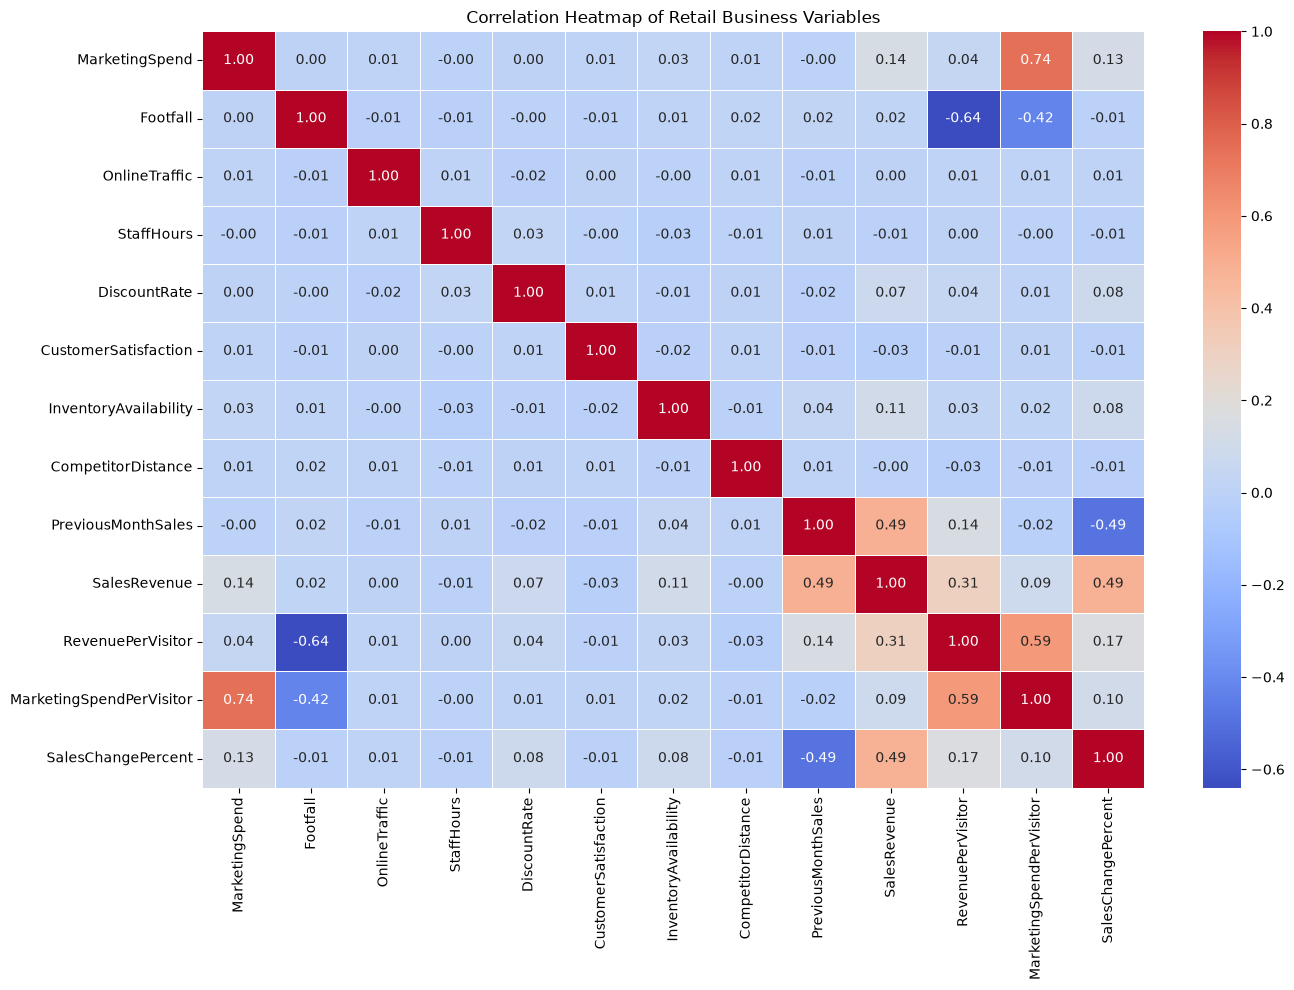

In [26]:

# TASK 1: Pivot Tables & Correlation Analysis
# Requirement: Visualise relationships between numerical variables using a correlation heatmap

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Retail Business Variables")
plt.tight_layout()
plt.show()


### Correlation Analysis – Key Findings

The correlation matrix and heatmap were used to investigate relationships between numerical business variables and SalesRevenue.

The strongest independent numerical relationship with SalesRevenue was PreviousMonthSales, with a positive correlation of 0.49. This suggests that stores with higher previous-month sales generally tend to achieve higher current sales revenue.

MarketingSpend had a weak positive correlation with SalesRevenue (0.14), while InventoryAvailability also showed a weak positive relationship (0.11). Other variables, including Footfall (0.02), OnlineTraffic (0.00) and CustomerSatisfaction (-0.03), showed very little linear correlation with revenue.

An interesting finding was that Footfall had almost no overall linear relationship with SalesRevenue. This suggests that higher visitor numbers alone do not necessarily correspond to higher revenue within this dataset.

The engineered features RevenuePerVisitor (0.31) and SalesChangePercent (0.49) also showed positive correlations with SalesRevenue. However, both features are calculated using SalesRevenue itself, so these relationships are partly mathematical and should not be interpreted as independent business drivers. They will therefore be excluded from the predictive models to avoid data leakage.

Overall, PreviousMonthSales appears to be the strongest independent numerical variable associated with SalesRevenue. The results also demonstrate that relationships between business variables vary considerably, providing useful information for the predictive modelling stage.

In [27]:

# TASK 1: Predictive Analytics
# Requirement: Prepare predictor variables and target variable for predictive modelling

from sklearn.model_selection import train_test_split

# Select independent variables (predictors)
X = retail_clean[
    [
        "MarketingSpend",
        "Footfall",
        "OnlineTraffic",
        "StaffHours",
        "DiscountRate",
        "CustomerSatisfaction",
        "InventoryAvailability",
        "CompetitorDistance",
        "PreviousMonthSales",
        "MarketingSpendPerVisitor",
        "Region",
        "StoreType",
        "Season"
    ]
]

# Select the variable we want to predict
y = retail_clean["SalesRevenue"]

# Convert categorical variables into numerical columns
X = pd.get_dummies(
    X,
    columns=["Region", "StoreType", "Season"],
    drop_first=True,
    dtype=int
)

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)


Training data: (4000, 18)
Testing data: (1000, 18)
Training target: (4000,)
Testing target: (1000,)


In [28]:

# TASK 1: Predictive Analytics
# Requirement: Train Model 1 - Linear Regression

from sklearn.linear_model import LinearRegression

# Create the Linear Regression model
linear_model = LinearRegression()

# Train the model using the training data
linear_model.fit(X_train, y_train)

# Generate predictions using the testing data
linear_predictions = linear_model.predict(X_test)

print("Linear Regression model trained successfully.")
print("Number of predictions:", len(linear_predictions))


Linear Regression model trained successfully.
Number of predictions: 1000


In [29]:
# TASK 1: Predictive Analytics
# Requirement: Train Model 2 - Random Forest Regression

from sklearn.ensemble import RandomForestRegressor

# Create the Random Forest model
random_forest_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model using the training data
random_forest_model.fit(X_train, y_train)

# Generate predictions using the testing data
random_forest_predictions = random_forest_model.predict(X_test)

print("Random Forest model trained successfully.")
print("Number of predictions:", len(random_forest_predictions))

Random Forest model trained successfully.
Number of predictions: 1000


In [30]:
# TASK 1: Predictive Analytics
# Requirement: Evaluate and compare models using MAE, RMSE and R²

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Calculate evaluation metrics for Linear Regression
linear_mae = mean_absolute_error(y_test, linear_predictions)
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_predictions))
linear_r2 = r2_score(y_test, linear_predictions)

# Calculate evaluation metrics for Random Forest
rf_mae = mean_absolute_error(y_test, random_forest_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, random_forest_predictions))
rf_r2 = r2_score(y_test, random_forest_predictions)

# Display results side by side
model_comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [linear_mae, rf_mae],
    "RMSE": [linear_rmse, rf_rmse],
    "R²": [linear_r2, rf_r2]
})

model_comparison.round(2)

,Model,MAE,RMSE,R²
0,Linear Regression,5195.33,6493.13,0.38
1,Random Forest,5171.67,6451.12,0.39


### Predictive Analytics – Model Comparison and Findings

Two regression models were developed to predict SalesRevenue: Linear Regression and Random Forest Regression.

Linear Regression was selected as a baseline model because it is relatively simple to understand and provides a useful starting point for predicting numerical outcomes. Random Forest Regression was selected as a second model because it combines multiple decision trees and can identify more complex, non-linear relationships within the data.

The dataset was divided into training and testing sets using an 80/20 split. This provided 4,000 observations for training and 1,000 observations for testing. Both models were trained using the same training data and evaluated against the same test data to ensure a fair comparison.

Random Forest achieved slightly better results across all three evaluation metrics. It recorded an MAE of 5,171.67, an RMSE of 6,451.12 and an R² of 0.39. Linear Regression recorded an MAE of 5,195.33, an RMSE of 6,493.13 and an R² of 0.38.

Although Random Forest performed marginally better, the difference between the models was small. The R² results indicate that the models explain approximately 38–39% of the variation in SalesRevenue. This suggests that the available variables provide some predictive value, but do not explain most of the differences in revenue.

Overall, Random Forest was the marginally better-performing model, although neither model achieved particularly strong predictive performance. These results demonstrate the limitations of the available dataset and the difficulty of predicting retail revenue using the selected variables.

**Limitation:** The dataset does not contain dates or a chronological sequence of observations. Therefore, the models evaluate predictions on held-out observations rather than forecasting future months using historical time-series data.

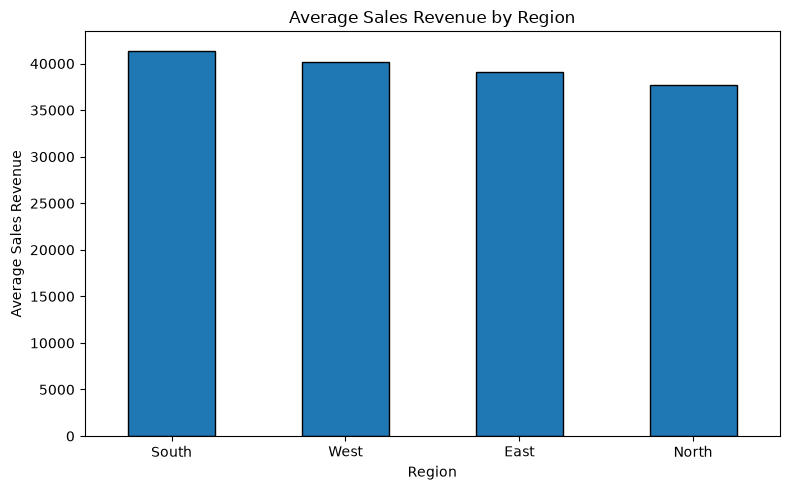

In [31]:

# TASK 1: Visualisations
# Requirement: Visualise average SalesRevenue by Region

# Calculate average revenue for each region
regional_revenue = retail_clean.groupby("Region")["SalesRevenue"].mean()

# Create the bar chart
plt.figure(figsize=(8, 5))
regional_revenue.sort_values(ascending=False).plot(
    kind="bar",
    edgecolor="black"
)

# Add chart labels and title
plt.title("Average Sales Revenue by Region")
plt.xlabel("Region")
plt.ylabel("Average Sales Revenue")
plt.xticks(rotation=0)

# Display the chart
plt.tight_layout()
plt.show()


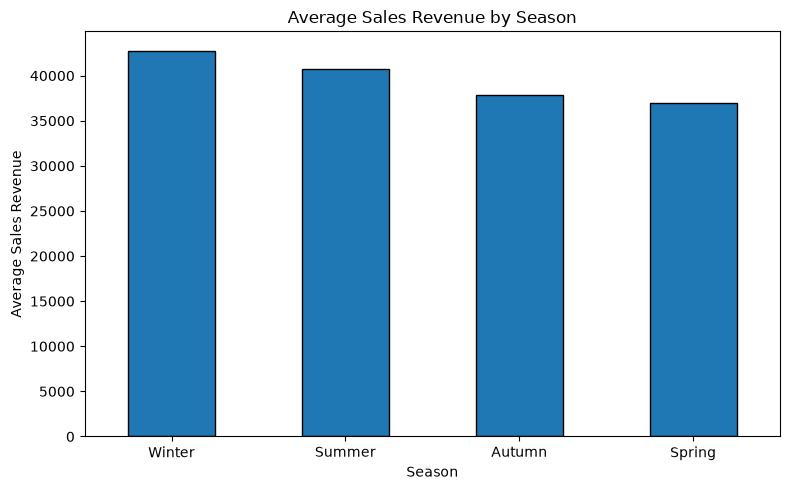

In [32]:

# TASK 1: Visualisations
# Requirement: Visualise average SalesRevenue by Season

# Calculate average revenue for each season
seasonal_revenue = retail_clean.groupby("Season")["SalesRevenue"].mean()

# Create the bar chart
plt.figure(figsize=(8, 5))
seasonal_revenue.sort_values(ascending=False).plot(
    kind="bar",
    edgecolor="black"
)

# Add chart labels and title
plt.title("Average Sales Revenue by Season")
plt.xlabel("Season")
plt.ylabel("Average Sales Revenue")
plt.xticks(rotation=0)

# Display the chart
plt.tight_layout()
plt.show()


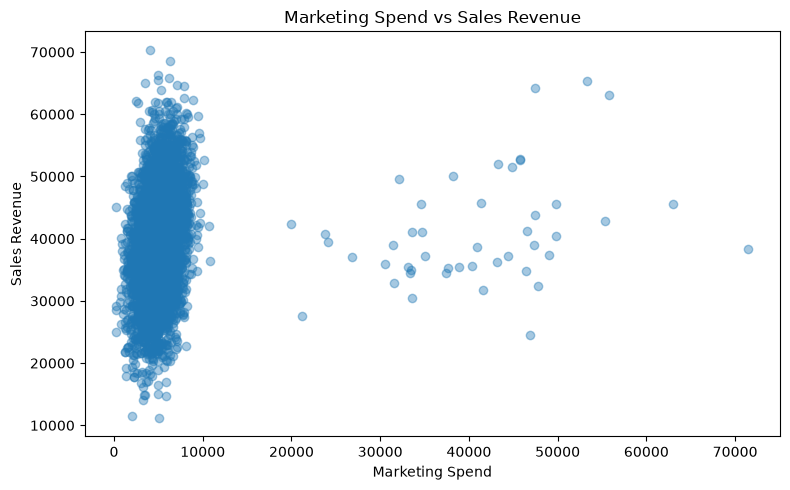

In [33]:

# TASK 1: Visualisations
# Requirement: Visualise the relationship between MarketingSpend and SalesRevenue

# Create the scatter plot
plt.figure(figsize=(8, 5))

plt.scatter(
    retail_clean["MarketingSpend"],
    retail_clean["SalesRevenue"],
    alpha=0.4
)

# Add chart labels and title
plt.title("Marketing Spend vs Sales Revenue")
plt.xlabel("Marketing Spend")
plt.ylabel("Sales Revenue")

# Display the chart
plt.tight_layout()
plt.show()


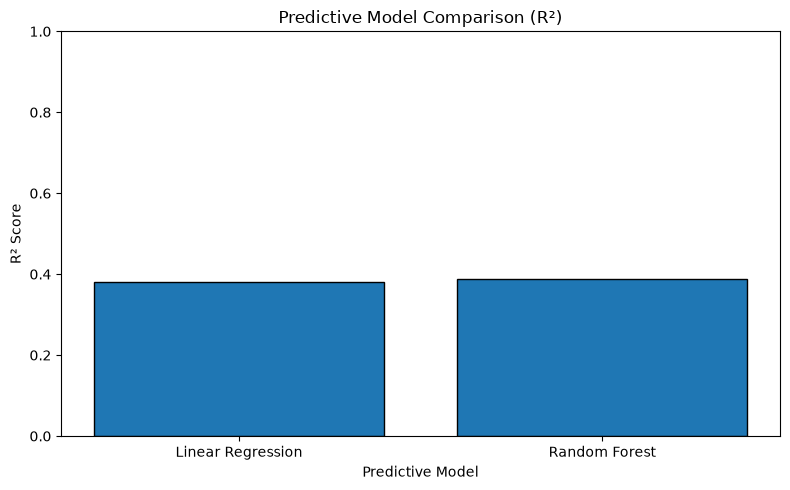

In [34]:

# TASK 1: Visualisations
# Requirement: Compare the predictive performance of both models using R²

# Store the R² results
model_r2 = {
    "Linear Regression": linear_r2,
    "Random Forest": rf_r2
}

# Create the bar chart
plt.figure(figsize=(8, 5))
plt.bar(
    model_r2.keys(),
    model_r2.values(),
    edgecolor="black"
)

# Add chart labels and title
plt.title("Predictive Model Comparison (R²)")
plt.xlabel("Predictive Model")
plt.ylabel("R² Score")
plt.ylim(0, 1)

# Display the chart
plt.tight_layout()
plt.show()
